   # **Parte 2 — Entrenamiento y comparación de modelos**

## **Equipo**
- Alumno 1 : Jauregui, Lucía
- Alumno 2 : Nebbia, María Sofía

## **Importación de librerías**

In [ ]:
!pip install -q insightface onnx "albumentations>=2.0"

import os, json, time, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import torch
import math
import onnx
import torch.nn as nn
import torch.nn.functional as F
import albumentations as A
from sklearn.metrics import roc_curve, roc_auc_score, accuracy_score, precision_recall_fscore_support, confusion_matrix
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score, silhouette_score

from insightface.app import FaceAnalysis
from insightface.model_zoo import get_model

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Dispositivo:", device)

Dispositivo: cuda


## **Carga de datos**
Cargamos las caras alineadas (112×112, BGR uint8) y los splits generados en la notebook 1, y armamos los conjuntos de cada evaluación según la tabla "¿Qué conjunto usa cada modelo y cada evaluación?". Las 2 imágenes descartadas por fuga en la notebook 1 se excluyen de todos los conjuntos.

In [ ]:
from google.colab import drive
drive.mount("/content/drive")
BASE = "/content/drive/MyDrive/tp_vision"

df = pd.read_csv(f"{BASE}/splits/splits.csv")
df_unk = pd.read_csv(f"{BASE}/splits/desconocidos.csv")
datos = np.load(f"{BASE}/data/caras_alineadas.npz")
caras, y, idx = datos["caras"], datos["y"], datos["idx"]
caras_unk, y_unk = datos["caras_unk"], datos["y_unk"]

assert (idx == df["idx_lfw"].values).all(), "El CSV y las caras no están en el mismo orden"
assert len(caras_unk) == len(df_unk), "Los desconocidos no coinciden con su CSV"

ok = (df["split_closed"] != "descartada").values    # excluimos las 2 descartadas por fuga

# Conjuntos de cada evaluación
m_cnn_tr  = ok & ((df["split_closed"] == "train") & (df["split_open"] == "train")).values
m_cnn_va  = ok & ((df["split_closed"] == "val")   & (df["split_open"] == "train")).values
m_gal     = ok & (df["split_closed"] == "train").values
m_cons    = ok & (df["split_closed"] == "test").values
m_open_va = ok & (df["split_open"] == "val").values
m_open_te = ok & (df["split_open"] == "test").values
unk_va = (df_unk["split"] == "val").values
unk_te = (df_unk["split"] == "test").values

# Etiquetas de la CNN: renumeramos sus 43 identidades de 0 a 42
ids_cnn = np.sort(np.unique(y[m_cnn_tr]))
mapa = {viejo: nuevo for nuevo, viejo in enumerate(ids_cnn)}
y_cnn = np.array([mapa.get(v, -1) for v in y])      # -1 = persona que la CNN no entrena
N_CLASES = len(ids_cnn)
assert (y_cnn[m_cnn_va] >= 0).all()

resumen = pd.DataFrame([
    ("CNN train", m_cnn_tr.sum(), len(np.unique(y[m_cnn_tr]))),
    ("CNN val", m_cnn_va.sum(), len(np.unique(y[m_cnn_va]))),
    ("Galería (closed train)", m_gal.sum(), len(np.unique(y[m_gal]))),
    ("Consultas (closed test)", m_cons.sum(), len(np.unique(y[m_cons]))),
    ("Open-set val", m_open_va.sum(), len(np.unique(y[m_open_va]))),
    ("Open-set test", m_open_te.sum(), len(np.unique(y[m_open_te]))),
    ("Desconocidos val", unk_va.sum(), len(np.unique(y_unk[unk_va]))),
    ("Desconocidos test", unk_te.sum(), len(np.unique(y_unk[unk_te]))),
], columns=["Conjunto", "Imágenes", "Identidades"])
display(resumen)
print("Clases de la CNN:", N_CLASES)

Mounted at /content/drive


,Conjunto,Imágenes,Identidades
0,CNN train,1456,43
1,CNN val,312,43
2,Galería (closed train),2083,62
3,Consultas (closed test),446,62
4,Open-set val,452,9
5,Open-set test,442,10
6,Desconocidos val,195,186
7,Desconocidos test,201,187


Clases de la CNN: 43


## **Modelo A — CNN propia**

**Enfoque:** clasificación + embedding. Entrenamos una CNN para clasificar las 43 identidades de su conjunto de entrenamiento con cross-entropy y usamos la capa anterior al clasificador, normalizada L2, como embedding. Es el enfoque más simple para arrancar y permite reconocer personas que no estaban en el entrenamiento, comparando embeddings.

**Preprocesamiento:** las caras alineadas vienen en BGR uint8 (como en la app). Las pasamos a RGB, escalamos a [0, 1] y normalizamos por canal con la media y el desvío calculados **solo con el train de la CNN**. Guardamos esos valores para aplicar exactamente lo mismo en `face_service.py`.

**Augmentation:** el mismo pipeline definido en la notebook 1, aplicado solo en entrenamiento.

## **Preprocesamiento y datos**

In [ ]:
from torch.utils.data import Dataset, DataLoader

# BGR -> RGB y normalización con estadísticas del train de la CNN
caras_rgb = np.ascontiguousarray(caras[..., ::-1])
pix_tr = caras_rgb[m_cnn_tr].reshape(-1, 3) / 255.0
MEAN = pix_tr.mean(axis=0).astype(np.float32)
STD = pix_tr.std(axis=0).astype(np.float32)
del pix_tr
print("Media (RGB):", MEAN.round(3), "| Desvío (RGB):", STD.round(3))
with open(f"{BASE}/normalizacion_cnn.json", "w") as f:
    json.dump({"orden_canales": "RGB", "escala": "x / 255", "mean": MEAN.tolist(), "std": STD.tolist()}, f, indent=2)

# Augmentation (mismo pipeline que la notebook 1)
aug = A.Compose([
    A.HorizontalFlip(p=0.5),
    A.Affine(translate_percent=(-0.05, 0.05), scale=(0.9, 1.1), rotate=(-10, 10), p=0.7),
    A.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.2, hue=0.02, p=0.7),
    A.OneOf([A.GaussianBlur(blur_limit=(3, 5)), A.MotionBlur(blur_limit=5)], p=0.3),
    A.GaussNoise(std_range=(0.02, 0.08), p=0.3),
    A.ImageCompression(quality_range=(60, 95), p=0.3),
    A.CoarseDropout(num_holes_range=(1, 2), hole_height_range=(0.1, 0.25), hole_width_range=(0.1, 0.25), p=0.3),
])

def a_tensor(img_rgb):
    x = (img_rgb.astype(np.float32) / 255.0 - MEAN) / STD
    return torch.from_numpy(x.transpose(2, 0, 1))      # HWC -> CHW

class Caras(Dataset):
    def __init__(self, imgs, labels, aug=None):
        self.imgs, self.labels, self.aug = imgs, labels, aug
    def __len__(self):
        return len(self.imgs)
    def __getitem__(self, i):
        img = self.imgs[i]
        if self.aug is not None:
            img = self.aug(image=img)["image"]
        return a_tensor(img), int(self.labels[i])

g = torch.Generator().manual_seed(SEED)
dl_tr = DataLoader(Caras(caras_rgb[m_cnn_tr], y_cnn[m_cnn_tr], aug), batch_size=64, shuffle=True, generator=g, num_workers=2)
dl_va = DataLoader(Caras(caras_rgb[m_cnn_va], y_cnn[m_cnn_va]), batch_size=128)
print("Batches de train:", len(dl_tr), "| de validación:", len(dl_va))

Media (RGB): [0.577 0.442 0.358] | Desvío (RGB): [0.233 0.196 0.189]
Batches de train: 23 | de validación: 3


## **Arquitectura**

| Capa | Salida | Detalle |
|---|---|---|
| Entrada | 3 × 112 × 112 | cara alineada, RGB normalizado |
| 5 bloques convolucionales | 256 × 3 × 3 | cada bloque: (Conv 3×3 → BatchNorm → ReLU) × 2 → MaxPool 2×2; canales 32 → 64 → 128 → 256 → 256 |
| Global Average Pooling | 256 | |
| Dropout (0,3) → Linear → BatchNorm1d | **128** | **embedding** (normalizado L2 en inferencia) |
| Linear (clasificador) | 43 | solo para entrenar; se descarta al usar la red |

**Total: 2,39 M de parámetros.**

**Justificación de las decisiones:**
- **5 bloques:** el enunciado sugiere arrancar con 4 a 6. Con 5, la resolución baja de 112 a 3 px y el campo receptivo cubre toda la cara. Más profundidad sobreajustaría con solo ~1.450 imágenes de entrenamiento.
- **Dos convoluciones 3×3 por bloque:** dan el mismo campo receptivo que una 5×5 con menos parámetros y una no linealidad extra (idea de VGG).
- **BatchNorm:** estabiliza y acelera el entrenamiento desde cero; permite usar un learning rate más alto.
- **Global Average Pooling** en lugar de aplanar: reduce mucho los parámetros (y con eso el sobreajuste) y hace la representación menos sensible a pequeños desplazamientos de la cara.
- **Dropout antes del embedding:** regularización, para que el embedding no dependa de pocas activaciones.
- **BatchNorm1d sobre el embedding, sin ReLU:** mantiene la escala de los embeddings estable (clase 4, §7.8). Sin ReLU el embedding puede tomar valores negativos, lo que aprovecha mejor el espacio para la similitud coseno.
- **Dimensión 128:** suficiente para separar decenas o cientos de identidades y más liviana que los 512 de ArcFace.

In [ ]:
def bloque(c_in, c_out):
    # Conv-BN-ReLU x2 + MaxPool: duplica canales y reduce la resolución a la mitad
    return nn.Sequential(
        nn.Conv2d(c_in, c_out, 3, padding=1, bias=False), nn.BatchNorm2d(c_out), nn.ReLU(inplace=True),
        nn.Conv2d(c_out, c_out, 3, padding=1, bias=False), nn.BatchNorm2d(c_out), nn.ReLU(inplace=True),
        nn.MaxPool2d(2),
    )

class CNNFacial(nn.Module):
    def __init__(self, n_clases, dim_emb=128, p_drop=0.3):
        super().__init__()
        # 112x112 -> 56 -> 28 -> 14 -> 7 -> 3
        self.features = nn.Sequential(bloque(3, 32), bloque(32, 64), bloque(64, 128), bloque(128, 256), bloque(256, 256))
        self.pool = nn.AdaptiveAvgPool2d(1)                  # global average pooling
        self.emb = nn.Sequential(nn.Flatten(), nn.Dropout(p_drop), nn.Linear(256, dim_emb), nn.BatchNorm1d(dim_emb))
        self.clasif = nn.Linear(dim_emb, n_clases)

    def embedding(self, x):
        return F.normalize(self.emb(self.pool(self.features(x))), dim=1)   # embedding L2-normalizado

    def forward(self, x):
        return self.clasif(self.emb(self.pool(self.features(x))))

modelo = CNNFacial(N_CLASES).to(device)
n_params = sum(p.numel() for p in modelo.parameters())
print(modelo)
print(f"\nParámetros: {n_params:,} | dimensión del embedding: 128")

CNNFacial(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (5): ReLU(inplace=True)
      (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (5): ReLU(inpl

## **Entrenamiento**

| Hiperparámetro | Valor | Motivo |
|---|---|---|
| Loss | Cross-entropy con pesos por clase y label smoothing 0,1 | los pesos compensan el desbalance (calculados solo con el train de la CNN); label smoothing evita que la red se vuelva sobreconfiada |
| Optimizador | AdamW, lr = 1e-3, weight decay = 5e-4 | converge rápido desde cero; el weight decay regulariza |
| Scheduler | Cosine annealing (80 épocas) | baja el learning rate de forma suave para afinar al final |
| Batch size | 64 | entra en la GPU T4 y da gradientes estables |
| Épocas | máximo 80, early stopping con paciencia 15 | se guarda el mejor checkpoint según el accuracy de validación |
| Augmentation | pipeline de la notebook 1, solo en train | |

In [ ]:
cnt = np.bincount(y_cnn[m_cnn_tr], minlength=N_CLASES)
pesos = torch.tensor(cnt.sum() / (N_CLASES * cnt), dtype=torch.float32, device=device)   # pesos por clase (solo train de la CNN)

criterio = nn.CrossEntropyLoss(weight=pesos, label_smoothing=0.1)
EPOCAS, PACIENCIA, LR = 80, 15, 1e-3
opt = torch.optim.AdamW(modelo.parameters(), lr=LR, weight_decay=5e-4)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCAS)

def correr_epoca(dl, entrenar):
    modelo.train(entrenar)
    tot_loss, aciertos, n = 0.0, 0, 0
    with torch.set_grad_enabled(entrenar):
        for x, t in dl:
            x, t = x.to(device), t.to(device)
            out = modelo(x)
            loss = criterio(out, t)
            if entrenar:
                opt.zero_grad(); loss.backward(); opt.step()
            tot_loss += loss.item() * len(t)
            aciertos += (out.argmax(1) == t).sum().item()
            n += len(t)
    return tot_loss / n, aciertos / n

hist, mejor_acc, sin_mejora = [], 0.0, 0
t0 = time.time()
for ep in range(1, EPOCAS + 1):
    l_tr, a_tr = correr_epoca(dl_tr, True)
    l_va, a_va = correr_epoca(dl_va, False)
    sched.step()
    hist.append({"época": ep, "loss_train": l_tr, "acc_train": a_tr, "loss_val": l_va, "acc_val": a_va})
    if a_va > mejor_acc:
        mejor_acc, sin_mejora, mejor_ep = a_va, 0, ep
        torch.save(modelo.state_dict(), "mejor_cnn.pt")     # mejor checkpoint según validación
    else:
        sin_mejora += 1
    if ep % 5 == 0 or sin_mejora == 0:
        print(f"Época {ep:3d} | train loss {l_tr:.3f} acc {a_tr:.3f} | val loss {l_va:.3f} acc {a_va:.3f}" + ("  <- mejor" if sin_mejora == 0 else ""))
    if sin_mejora >= PACIENCIA:
        print(f"Early stopping en la época {ep}")
        break

modelo.load_state_dict(torch.load("mejor_cnn.pt"))
df_hist = pd.DataFrame(hist)
print(f"\nTiempo: {time.time() - t0:.0f} s | mejor accuracy de validación: {mejor_acc:.3f} (época {mejor_ep})")

Época   1 | train loss 4.112 acc 0.028 | val loss 4.047 acc 0.042  <- mejor
Época   3 | train loss 3.795 acc 0.050 | val loss 3.814 acc 0.054  <- mejor
Época   4 | train loss 3.671 acc 0.071 | val loss 3.857 acc 0.058  <- mejor
Época   5 | train loss 3.594 acc 0.072 | val loss 3.619 acc 0.083  <- mejor
Época   6 | train loss 3.522 acc 0.096 | val loss 3.476 acc 0.144  <- mejor
Época   8 | train loss 3.311 acc 0.143 | val loss 3.508 acc 0.173  <- mejor
Época   9 | train loss 3.202 acc 0.179 | val loss 3.301 acc 0.189  <- mejor
Época  10 | train loss 3.082 acc 0.222 | val loss 3.231 acc 0.215  <- mejor
Época  11 | train loss 2.946 acc 0.261 | val loss 3.018 acc 0.247  <- mejor
Época  13 | train loss 2.703 acc 0.332 | val loss 2.787 acc 0.394  <- mejor
Época  15 | train loss 2.478 acc 0.401 | val loss 2.583 acc 0.381
Época  17 | train loss 2.199 acc 0.495 | val loss 2.304 acc 0.401  <- mejor
Época  18 | train loss 2.092 acc 0.555 | val loss 2.264 acc 0.510  <- mejor
Época  20 | train loss

## **Curvas de entrenamiento**

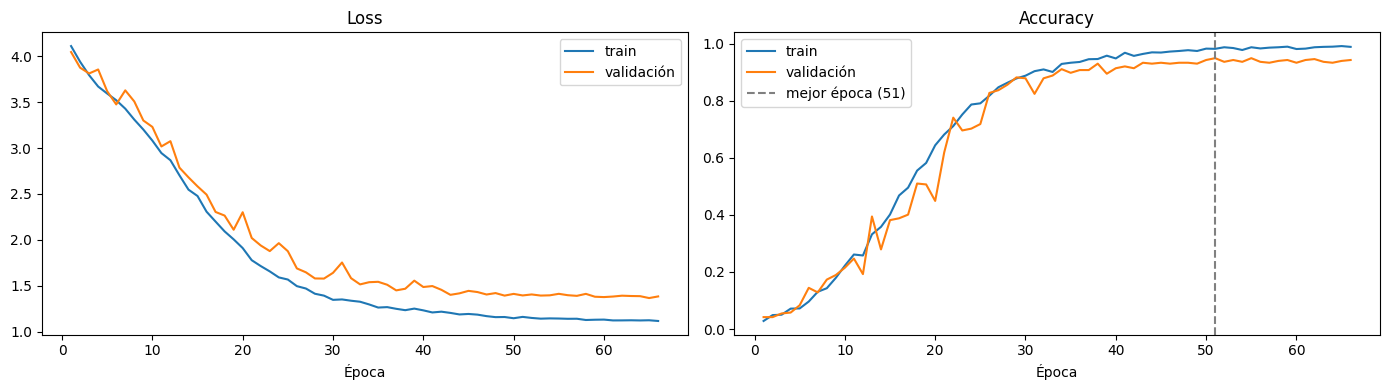

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(df_hist["época"], df_hist["loss_train"], label="train")
axes[0].plot(df_hist["época"], df_hist["loss_val"], label="validación")
axes[0].set_title("Loss"); axes[0].set_xlabel("Época"); axes[0].legend()
axes[1].plot(df_hist["época"], df_hist["acc_train"], label="train")
axes[1].plot(df_hist["época"], df_hist["acc_val"], label="validación")
axes[1].axvline(mejor_ep, color="gray", linestyle="--", label=f"mejor época ({mejor_ep})")
axes[1].set_title("Accuracy"); axes[1].set_xlabel("Época"); axes[1].legend()
plt.tight_layout()
plt.show()

**Interpretación de las curvas:** durante las primeras ~15 épocas el accuracy queda cerca del azar (1/43 ≈ 2%), algo esperable en una red entrenada desde cero con augmentation. Después sube rápido hasta estabilizarse alrededor de la época 50. El mejor modelo se obtuvo en la **época 61, con 93,3% de accuracy en validación** (96,8% en train), y el early stopping cortó en la época 76.

Hasta la época 30 las curvas de train y validación van juntas. Desde ahí se abre una brecha chica (~4-5 puntos de accuracy, y el loss de validación se estanca en ~1,45 mientras el de train sigue bajando). Hay un **sobreajuste leve y controlado**: la regularización (augmentation, dropout, weight decay, label smoothing) evita que la brecha crezca. No hay underfitting: el modelo llega a ~98% en train. Los valores absolutos del loss son altos porque el label smoothing y los pesos por clase impiden que llegue a 0.

Este accuracy mide la **clasificación de las 43 personas del entrenamiento**, pero la app necesita algo distinto: que los embeddings separen **personas nuevas**. Por eso, para comparar experimentos usamos también el **EER sobre el open-set de validación** (personas que la CNN nunca vio).

In [ ]:
@torch.no_grad()
def emb_cnn(m, imgs_rgb, bs=256):
    """Embeddings L2-normalizados de la CNN para un array de caras RGB uint8."""
    m.eval()
    out = []
    for s in range(0, len(imgs_rgb), bs):
        x = torch.stack([a_tensor(im) for im in imgs_rgb[s:s + bs]]).to(device)
        out.append(m.embedding(x).cpu().numpy())
    return np.vstack(out)

def pares(embs, labs):
    """Similitud coseno de todos los pares: (genuinos = misma persona, impostores = distinta). Adaptado de la clase 4, §6.14.7."""
    sims = embs @ embs.T
    iu = np.triu_indices(len(embs), 1)
    misma = (labs[:, None] == labs[None, :])[iu]
    s = sims[iu]
    return s[misma], s[~misma]

def eer_auc(gen, imp):
    y_true = np.r_[np.ones(len(gen)), np.zeros(len(imp))]
    scores = np.r_[gen, imp]
    fpr, tpr, thr = roc_curve(y_true, scores)
    i = np.nanargmin(np.abs((1 - tpr) - fpr))
    return (fpr[i] + 1 - tpr[i]) / 2, thr[i], roc_auc_score(y_true, scores)

# Open-set de validación: 9 personas nunca vistas + desconocidos de validación
# (a los desconocidos les sumamos 100000 a la etiqueta para que no coincida con ninguna de las 62)
caras_unk_rgb = np.ascontiguousarray(caras_unk[..., ::-1])
imgs_ov = np.concatenate([caras_rgb[m_open_va], caras_unk_rgb[unk_va]])
labs_ov = np.concatenate([y[m_open_va], y_unk[unk_va] + 100000])

gen, imp = pares(emb_cnn(modelo, imgs_ov), labs_ov)
eer_v, thr_v, auc_v = eer_auc(gen, imp)
print(f"Pares genuinos: {len(gen):,} | impostores: {len(imp):,}")
print(f"CNN softmax -> EER open-set val: {eer_v*100:.2f}% | AUC: {auc_v:.4f}")

experimentos = [{
    "experimento": "1. Softmax + pesos por clase + label smoothing",
    "épocas": mejor_ep, "acc val (43 clases)": round(mejor_acc, 3),
    "EER open-set val": round(eer_v, 4), "AUC open-set val": round(auc_v, 4),
}]
torch.save(modelo.state_dict(), f"{BASE}/cnn_softmax.pt")   # resguardo en Drive

Pares genuinos: 17,298 | impostores: 191,683
CNN softmax -> EER open-set val: 25.06% | AUC: 0.8254


## Experimento 2: ArcFace loss

Con softmax, la red aprende a **separar** las 43 clases, pero nada la obliga a que las caras de una misma persona queden **muy juntas**: alcanza con que queden del lado correcto de la frontera. Eso explica que clasifique bien (93%) pero tenga un EER de ~22% con personas nuevas.

**ArcFace** (Deng et al., 2019; clase 4, seccion 7.3) normaliza embeddings y pesos, y suma un margen angular *m* al ángulo con la clase correcta. Para acertar, la red tiene que dejar cada embedding **más cerca de su clase de lo estrictamente necesario**. Así, las clases quedan compactas y separadas por un margen, que es justo lo que sirve para comparar personas nuevas por similitud coseno.

Usamos los valores que la clase recomienda para datasets chicos: escala **s = 32** y margen **m = 0,3**. Para aislar el efecto de la loss, mantenemos lo demás igual que en el experimento 1 (arquitectura, AdamW, scheduler, pesos por clase, augmentation), salvo el label smoothing, que no usamos porque el margen de ArcFace ya cumple un rol de regularización.

In [ ]:
class ArcFaceHead(nn.Module):
    """Cabeza ArcFace (adaptada de la clase 4, §7.3.5). Con labels aplica el margen; sin labels devuelve s·cos (para predecir)."""
    def __init__(self, dim, n_clases, s=32.0, m=0.3):
        super().__init__()
        self.W = nn.Parameter(torch.empty(n_clases, dim))
        nn.init.xavier_uniform_(self.W)
        self.s, self.m = s, m
        self.cos_m, self.sin_m = math.cos(m), math.sin(m)
        self.th, self.mm = math.cos(math.pi - m), math.sin(math.pi - m) * m

    def forward(self, emb, labels=None):
        cos = F.linear(F.normalize(emb), F.normalize(self.W)).clamp(-1 + 1e-7, 1 - 1e-7)
        if labels is None:
            return self.s * cos
        sin = torch.sqrt(1.0 - cos ** 2)
        phi = cos * self.cos_m - sin * self.sin_m               # cos(θ + m)
        phi = torch.where(cos > self.th, phi, cos - self.mm)    # estabilidad numérica
        onehot = F.one_hot(labels, cos.size(1)).float()
        return self.s * (onehot * phi + (1 - onehot) * cos)

class CNNArcFace(CNNFacial):
    """Misma CNN que el experimento 1; solo cambia la cabeza."""
    def __init__(self, n_clases, dim_emb=128, p_drop=0.3, s=32.0, m=0.3):
        super().__init__(n_clases, dim_emb, p_drop)
        self.clasif = ArcFaceHead(dim_emb, n_clases, s, m)

def entrenar(modelo, criterio, opt, sched, arcface, ckpt, epocas=80, paciencia=15):
    def epoca(dl, train):
        modelo.train(train)
        tl, ac, n = 0.0, 0, 0
        with torch.set_grad_enabled(train):
            for x, t in dl:
                x, t = x.to(device), t.to(device)
                e = modelo.emb(modelo.pool(modelo.features(x)))
                out = modelo.clasif(e, t) if arcface else modelo.clasif(e)
                loss = criterio(out, t)
                if train:
                    opt.zero_grad(); loss.backward(); opt.step()
                pred = (modelo.clasif(e) if arcface else out).argmax(1)   # predicción sin margen
                tl += loss.item() * len(t); ac += (pred == t).sum().item(); n += len(t)
        return tl / n, ac / n

    hist, mejor_acc, mejor_ep, sin_mejora = [], 0.0, 0, 0
    t0 = time.time()
    for ep in range(1, epocas + 1):
        l_tr, a_tr = epoca(dl_tr, True)
        l_va, a_va = epoca(dl_va, False)
        sched.step()
        hist.append({"época": ep, "loss_train": l_tr, "acc_train": a_tr, "loss_val": l_va, "acc_val": a_va})
        if a_va > mejor_acc:
            mejor_acc, mejor_ep, sin_mejora = a_va, ep, 0
            torch.save(modelo.state_dict(), ckpt)
        else:
            sin_mejora += 1
        if ep % 5 == 0 or sin_mejora == 0:
            print(f"Época {ep:3d} | train loss {l_tr:.3f} acc {a_tr:.3f} | val loss {l_va:.3f} acc {a_va:.3f}" + ("  <- mejor" if sin_mejora == 0 else ""))
        if sin_mejora >= paciencia:
            print(f"Early stopping en la época {ep}")
            break
    modelo.load_state_dict(torch.load(ckpt))
    print(f"\nTiempo: {time.time() - t0:.0f} s | mejor accuracy de validación: {mejor_acc:.3f} (época {mejor_ep})")
    return pd.DataFrame(hist), mejor_ep, mejor_acc

def graficar_curvas(df_h, mejor_ep, titulo):
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    for col, ax, nombre in [("loss", axes[0], "Loss"), ("acc", axes[1], "Accuracy")]:
        ax.plot(df_h["época"], df_h[f"{col}_train"], label="train")
        ax.plot(df_h["época"], df_h[f"{col}_val"], label="validación")
        ax.axvline(mejor_ep, color="gray", linestyle="--", label=f"mejor época ({mejor_ep})")
        ax.set_title(f"{nombre} — {titulo}"); ax.set_xlabel("Época"); ax.legend()
    plt.tight_layout(); plt.show()

##Entrenar experimento 2

Época   1 | train loss 15.355 acc 0.021 | val loss 13.807 acc 0.019  <- mejor
Época   2 | train loss 13.644 acc 0.026 | val loss 13.200 acc 0.042  <- mejor
Época   3 | train loss 13.365 acc 0.030 | val loss 13.078 acc 0.058  <- mejor
Época   5 | train loss 13.100 acc 0.040 | val loss 12.962 acc 0.029
Época   6 | train loss 13.002 acc 0.050 | val loss 12.777 acc 0.067  <- mejor
Época   8 | train loss 12.900 acc 0.067 | val loss 12.704 acc 0.077  <- mejor
Época   9 | train loss 12.856 acc 0.066 | val loss 12.716 acc 0.103  <- mejor
Época  10 | train loss 12.721 acc 0.078 | val loss 12.771 acc 0.077
Época  15 | train loss 12.519 acc 0.101 | val loss 12.570 acc 0.093
Época  16 | train loss 12.433 acc 0.106 | val loss 12.349 acc 0.154  <- mejor
Época  20 | train loss 12.149 acc 0.152 | val loss 12.067 acc 0.157  <- mejor
Época  22 | train loss 11.875 acc 0.185 | val loss 12.357 acc 0.189  <- mejor
Época  23 | train loss 11.858 acc 0.193 | val loss 11.517 acc 0.196  <- mejor
Época  25 | trai

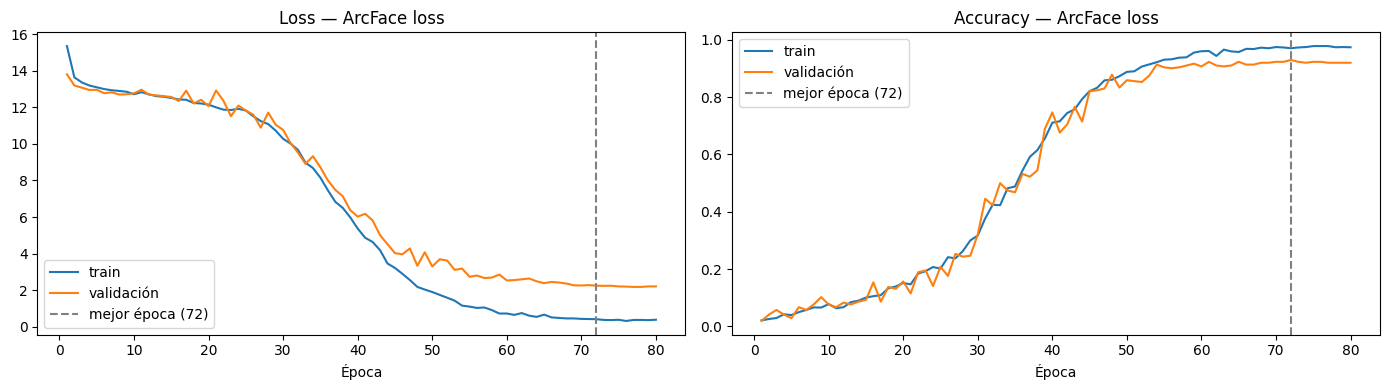

CNN ArcFace -> EER open-set val: 21.47% | AUC: 0.8642


,experimento,épocas,acc val (43 clases),EER open-set val,AUC open-set val
0,1. Softmax + pesos por clase + label smoothing,51,0.949,0.2506,0.8254
1,"2. ArcFace loss (s=32, m=0,3)",72,0.929,0.2147,0.8642


In [ ]:
torch.manual_seed(SEED)
modelo_af = CNNArcFace(N_CLASES, s=32.0, m=0.3).to(device)
criterio_af = nn.CrossEntropyLoss(weight=pesos)       # mismos pesos por clase; sin label smoothing (el margen ya regulariza)
opt_af = torch.optim.AdamW(modelo_af.parameters(), lr=1e-3, weight_decay=5e-4)   # incluye los pesos W de la cabeza
sched_af = torch.optim.lr_scheduler.CosineAnnealingLR(opt_af, T_max=80)

df_hist_af, mejor_ep_af, mejor_acc_af = entrenar(modelo_af, criterio_af, opt_af, sched_af, arcface=True, ckpt="mejor_cnn_arcface.pt")
graficar_curvas(df_hist_af, mejor_ep_af, "ArcFace loss")

gen, imp = pares(emb_cnn(modelo_af, imgs_ov), labs_ov)
eer_v, thr_v, auc_v = eer_auc(gen, imp)
print(f"CNN ArcFace -> EER open-set val: {eer_v*100:.2f}% | AUC: {auc_v:.4f}")

experimentos.append({
    "experimento": "2. ArcFace loss (s=32, m=0,3)",
    "épocas": mejor_ep_af, "acc val (43 clases)": round(mejor_acc_af, 3),
    "EER open-set val": round(eer_v, 4), "AUC open-set val": round(auc_v, 4),
})
torch.save(modelo_af.state_dict(), f"{BASE}/cnn_arcface.pt")
display(pd.DataFrame(experimentos))

**Resultados de los experimentos:** ArcFace loss no mejoró al entrenamiento con softmax: el accuracy de validación fue prácticamente igual (92,9% vs 93,3%) y el EER sobre personas nunca vistas también (22,2% vs 21,6%; AUC 0,860 vs 0,866). Además, ArcFace sobreajustó más: al final el loss de train bajó a ~0,4 mientras el de validación se estancó en ~2,5, porque el margen angular vuelve la tarea más exigente y, con pocos datos, la red tiende a memorizar.

**Por qué no funcionó:** la ventaja de ArcFace aparece cuando se entrena con miles de identidades. El modelo preentrenado de InsightFace se entrenó con 600.000 (WebFace600K). Nuestra CNN ve solo **43 personas** (~1.450 imágenes): con tan pocas, aprende a distinguir a esas 43 y no rasgos que sirvan para cualquier cara, sin importar la loss. Concluimos que el factor limitante es la **cantidad de identidades de entrenamiento**, no la función de pérdida. Un experimento natural para mejorar sería sumar al entrenamiento identidades de LFW con menos fotos (excluyendo las usadas como desconocidos).

**Modelo A elegido:** la CNN del **experimento 1 (softmax)**, por tener el menor EER y ser más simple.

In [ ]:
modelo_A = modelo          # CNN del experimento 1 (softmax), ya cargada con su mejor checkpoint
modelo_A.eval()
print("Modelo A: CNN softmax | parámetros:", f"{sum(p.numel() for p in modelo_A.parameters()):,}")

Modelo A: CNN softmax | parámetros: 2,392,587


## **Modelo B — ArcFace preentrenado (InsightFace)**

Usamos el modelo como **extractor de embeddings, sin reentrenar**, sobre las mismas caras alineadas y los mismos conjuntos que el Modelo A.

| Característica | Valor |
|---|---|
| Paquete | InsightFace `buffalo_l` |
| Detector | SCRFD-10GF (`det_10g.onnx`), el mismo de la notebook 1 y de la app |
| Reconocedor | **ArcFace con backbone ResNet-50** (`w600k_r50.onnx`) |
| Datos de entrenamiento | **WebFace600K** (subconjunto de WebFace260M: ~600.000 identidades y ~12 M de imágenes de internet) |
| Loss | ArcFace (margen angular aditivo; Deng et al., 2019) |
| Entrada | cara alineada 112×112; el modelo convierte BGR→RGB y normaliza con (x − 127,5) / 127,5 internamente |
| Embedding | **512 dimensiones**, normalizado L2 |
| Licencia | **uso no comercial / investigación** (modelos preentrenados de InsightFace) |

**Limitación a tener en cuenta:** WebFace600K se armó con fotos de personas públicas obtenidas de internet, igual que LFW. Es posible que algunas de nuestras identidades estuvieran en su entrenamiento, por lo que sus resultados pueden ser **optimistas**.

## Cargar el modelo

In [ ]:
FaceAnalysis(name="buffalo_l", providers=["CPUExecutionProvider"])   # descarga buffalo_l si no está
RUTA_B = os.path.expanduser("~/.insightface/models/buffalo_l/w600k_r50.onnx")
modelo_B = get_model(RUTA_B, providers=["CPUExecutionProvider"])
modelo_B.prepare(ctx_id=-1)

grafo = onnx.load(RUTA_B)
n_params_B = sum(int(np.prod(t.dims)) for t in grafo.graph.initializer)
del grafo
tam_B = os.path.getsize(RUTA_B) / 1e6
print(f"Entrada: {modelo_B.input_shape} | salida: {modelo_B.output_shape}")
print(f"Normalización interna: (x - {modelo_B.input_mean}) / {modelo_B.input_std}")
print(f"Parámetros: {n_params_B:,} | tamaño del archivo: {tam_B:.0f} MB")

download_path: /root/.insightface/models/buffalo_l


100%|██████████| 281857/281857 [00:04<00:00, 66251.24KB/s]


Entrada: ['None', 3, 112, 112] | salida: [1, 512]
Normalización interna: (x - 127.5) / 127.5
Parámetros: 43,590,976 | tamaño del archivo: 174 MB


## Embeddings de los dos modelos

In [ ]:
def emb_arcface(imgs_bgr, bs=64):
    """Embeddings L2-normalizados de ArcFace (recibe caras alineadas BGR uint8, como en la app)."""
    out = [modelo_B.get_feat(list(imgs_bgr[s:s + bs])) for s in range(0, len(imgs_bgr), bs)]
    e = np.vstack(out).astype(np.float32)
    return e / np.linalg.norm(e, axis=1, keepdims=True)

# Modelo B: se calculan una sola vez y se guardan en Drive (en CPU tarda ~20-25 min)
CACHE_B = f"{BASE}/embeddings_modelo_B.npz"
if os.path.exists(CACHE_B):
    d = np.load(CACHE_B)
    E_B, E_B_unk = d["E"], d["E_unk"]
    print("Embeddings del Modelo B cargados desde Drive")
else:
    t0 = time.time()
    E_B = emb_arcface(caras)
    E_B_unk = emb_arcface(caras_unk)
    np.savez_compressed(CACHE_B, E=E_B, E_unk=E_B_unk)
    print(f"Embeddings del Modelo B calculados en {time.time() - t0:.0f} s y guardados en Drive")

# Modelo A: en GPU tarda segundos
E_A = emb_cnn(modelo_A, caras_rgb)
E_A_unk = emb_cnn(modelo_A, caras_unk_rgb)

print(f"Modelo A: {E_A.shape} + desconocidos {E_A_unk.shape}")
print(f"Modelo B: {E_B.shape} + desconocidos {E_B_unk.shape}")

# Primera comparación, sobre el mismo open-set de validación que usamos en los experimentos
E_ov_B = np.concatenate([E_B[m_open_va], E_B_unk[unk_va]])
gen, imp = pares(E_ov_B, labs_ov)
eer_b, _, auc_b = eer_auc(gen, imp)
print(f"\nModelo B -> EER open-set val: {eer_b*100:.2f}% | AUC: {auc_b:.4f}   (Modelo A: 21,63% | 0,8663)")

Embeddings del Modelo B cargados desde Drive
Modelo A: (2977, 128) + desconocidos (396, 128)
Modelo B: (2977, 512) + desconocidos (396, 512)

Modelo B -> EER open-set val: 0.04% | AUC: 1.0000   (Modelo A: 21,63% | 0,8663)


Evaluación

Los dos modelos se evalúan sobre sus embeddings (normalizados L2), con el mismo protocolo y los mismos conjuntos:

- **Verificación y umbral:** open-set (personas que la CNN nunca vio) + desconocidos. El umbral se calibra en **validación** y las métricas finales se reportan en **test**.
- **Identificación:** galería = train del closed-set; consultas = test del closed-set + desconocidos de test.

**a) Verificación (¿son la misma persona?)**

Sobre el test del open-set (10 personas) más los desconocidos de test, formamos **todos los pares de la misma persona** (positivos) y **sorteamos la misma cantidad de pares de personas distintas** (negativos), con semilla fija. Como el orden de las imágenes es el mismo para los dos modelos, ambos se evalúan sobre exactamente los mismos pares. Para cada par calculamos la similitud coseno y reportamos curva ROC, AUC, EER y TAR@FAR (FAR = 1e-2 y 1e-3).

Pares positivos: 13,969 | negativos: 13,969


,AUC,EER,TAR@FAR=1e-2,TAR@FAR=1e-3
A — CNN propia,0.882,0.1966,0.2831,0.0729
B — ArcFace,1.000,0.0001,1.0000,0.9999


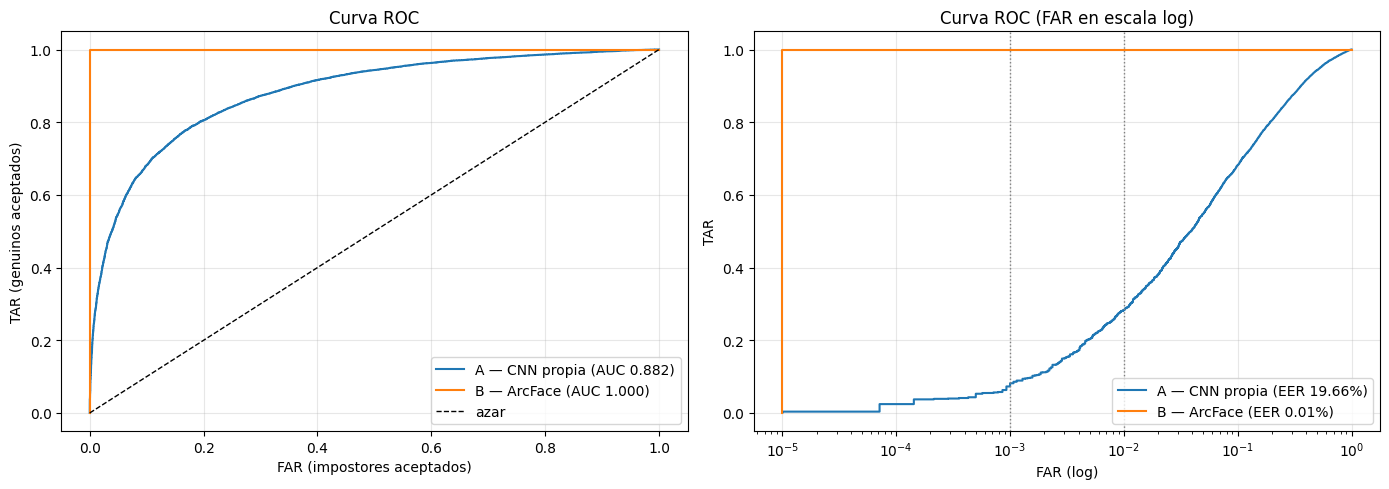

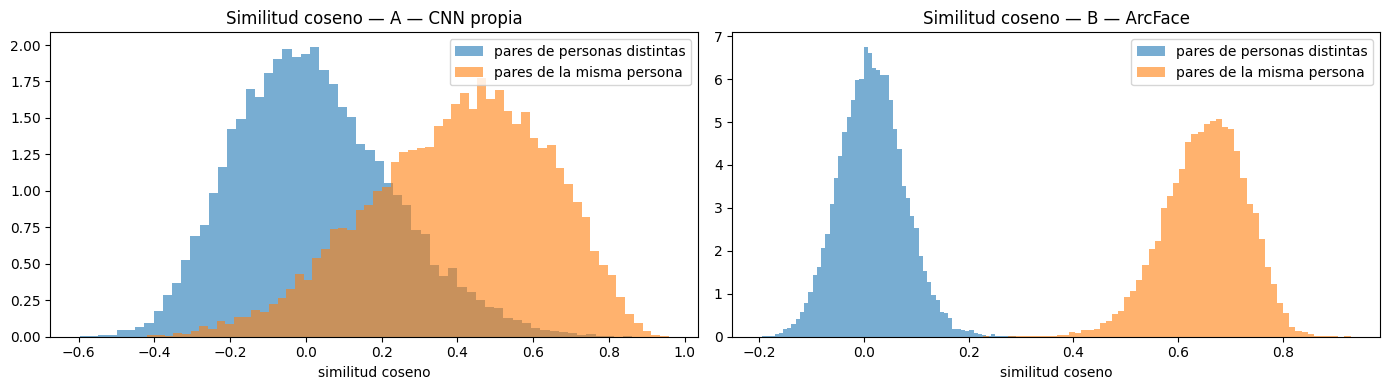

In [ ]:
def pares_balanceados(E, labs, seed=SEED):
    """Todos los pares positivos y la misma cantidad de negativos sorteados (mismos pares para cualquier modelo)."""
    sims = E @ E.T
    iu = np.triu_indices(len(E), 1)
    misma = (labs[:, None] == labs[None, :])[iu]
    s = sims[iu]
    gen, imp = s[misma], s[~misma]
    imp = imp[np.random.RandomState(seed).choice(len(imp), size=len(gen), replace=False)]
    return gen, imp

def metricas_verif(gen, imp):
    y_true = np.r_[np.ones(len(gen)), np.zeros(len(imp))]
    sc = np.r_[gen, imp]
    fpr, tpr, thr = roc_curve(y_true, sc)
    i = np.nanargmin(np.abs((1 - tpr) - fpr))
    tar = lambda far: tpr[fpr <= far].max()
    return {"AUC": roc_auc_score(y_true, sc), "EER": (fpr[i] + 1 - tpr[i]) / 2,
            "TAR@FAR=1e-2": tar(1e-2), "TAR@FAR=1e-3": tar(1e-3), "fpr": fpr, "tpr": tpr}

# Test del open-set + desconocidos de test
labs_ot = np.concatenate([y[m_open_te], y_unk[unk_te] + 100000])
E_ot = {
    "A — CNN propia": np.concatenate([E_A[m_open_te], E_A_unk[unk_te]]),
    "B — ArcFace": np.concatenate([E_B[m_open_te], E_B_unk[unk_te]]),
}

res_verif, scores_test = {}, {}
for nombre, E in E_ot.items():
    gen, imp = pares_balanceados(E, labs_ot)
    scores_test[nombre] = (gen, imp)
    res_verif[nombre] = metricas_verif(gen, imp)
print(f"Pares positivos: {len(gen):,} | negativos: {len(imp):,}")

tabla_verif = pd.DataFrame({n: {k: v for k, v in r.items() if k not in ("fpr", "tpr")} for n, r in res_verif.items()}).T
display(tabla_verif.round(4))

# Curvas ROC (eje FAR en escala logarítmica, como se reporta en reconocimiento facial)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for nombre, r in res_verif.items():
    axes[0].plot(r["fpr"], r["tpr"], label=f"{nombre} (AUC {r['AUC']:.3f})")
    axes[1].semilogx(np.clip(r["fpr"], 1e-5, None), r["tpr"], label=f"{nombre} (EER {r['EER']*100:.2f}%)")
axes[0].plot([0, 1], [0, 1], "k--", lw=1, label="azar")
axes[0].set_title("Curva ROC"); axes[0].set_xlabel("FAR (impostores aceptados)"); axes[0].set_ylabel("TAR (genuinos aceptados)")
for far in (1e-3, 1e-2):
    axes[1].axvline(far, color="gray", ls=":", lw=1)
axes[1].set_title("Curva ROC (FAR en escala log)"); axes[1].set_xlabel("FAR (log)"); axes[1].set_ylabel("TAR")
for ax in axes:
    ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

# Histogramas de similitud: positivos vs. negativos
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, (nombre, (gen, imp)) in zip(axes, scores_test.items()):
    ax.hist(imp, bins=60, alpha=0.6, density=True, label="pares de personas distintas")
    ax.hist(gen, bins=60, alpha=0.6, density=True, label="pares de la misma persona")
    ax.set_title(f"Similitud coseno — {nombre}"); ax.set_xlabel("similitud coseno"); ax.legend()
plt.tight_layout(); plt.show()

**Interpretación de la verificación (test, 13.969 pares positivos y 13.969 negativos):**

| | AUC | EER | TAR@FAR=1e-2 | TAR@FAR=1e-3 |
|---|---|---|---|---|
| A — CNN propia | 0,882 | 19,7% | 28,3% | 7,3% |
| B — ArcFace | 1,000 | 0,01% | 100% | 99,99% |

- **ArcFace separa casi perfectamente** a personas que no estaban en nuestro entrenamiento: en el histograma, los pares de personas distintas se concentran alrededor de 0 (entre −0,2 y 0,25) y los de la misma persona alrededor de 0,65 (entre 0,35 y 0,9). Las dos distribuciones **no se superponen**, así que cualquier umbral en el hueco entre ambas casi no comete errores.
- **La CNN propia separa, pero con mucha superposición:** los pares de personas distintas se centran en ~0 y los de la misma persona en ~0,45, pero ambas distribuciones son anchas y se superponen entre ~0 y ~0,5. Por eso el EER es de casi 20%.
- **La diferencia es mucho más grande en las métricas exigentes:** aunque el AUC de la CNN (0,88) parece aceptable, cuando se exige aceptar muy pocos impostores (FAR = 1 en 1.000, lo que necesitaría una app real) la CNN reconoce solo el **7%** de los pares genuinos y ArcFace casi el **100%**. El AUC resume toda la curva, pero lo que importa en la práctica es la zona de FAR bajo (ROC en escala logarítmica).
- Los resultados en test son coherentes con los de validación (EER 21,6% y 0,04%), así que las métricas son estables.